In [ ]:
import pandas as pd
import numpy as np
import warnings
warnings.filterwarnings ('ignore')
import seaborn as sns
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import  SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import confusion_matrix
from sklearn.metrics import r2_score
from sklearn.metrics import accuracy_score
from sklearn.metrics import classification_report
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline as SkPipeline

cols = [
    'fixed acidity', 'volatile acidity', 'citric acid',
    'residual sugar', 'chlorides', 'free sulfur dioxide',
    'total sulfur dioxide', 'density', 'pH',
    'sulphates', 'alcohol', 'quality'
]

df = pd.read_csv('Data/winequality.csv',
    sep=";",
    skiprows=1,      # skip the bad header
    names=cols       # provide correct column names
)

print(df.head())
print(df.columns)

   fixed acidity  volatile acidity  citric acid  residual sugar  chlorides  \
0            7.0              0.27         0.36            20.7      0.045   
1            6.3              0.30         0.34             1.6      0.049   
2            8.1              0.28         0.40             6.9      0.050   
3            7.2              0.23         0.32             8.5      0.058   
4            7.2              0.23         0.32             8.5      0.058   

   free sulfur dioxide  total sulfur dioxide  density    pH  sulphates  \
0                 45.0                 170.0   1.0010  3.00       0.45   
1                 14.0                 132.0   0.9940  3.30       0.49   
2                 30.0                  97.0   0.9951  3.26       0.44   
3                 47.0                 186.0   0.9956  3.19       0.40   
4                 47.0                 186.0   0.9956  3.19       0.40   

   alcohol  quality  
0      8.8        6  
1      9.5        6  
2     10.1        6 

In [ ]:
print(df.shape)

(4898, 12)


In [ ]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 4898 entries, 0 to 4897
Data columns (total 12 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   fixed acidity         4898 non-null   float64
 1   volatile acidity      4898 non-null   float64
 2   citric acid           4898 non-null   float64
 3   residual sugar        4898 non-null   float64
 4   chlorides             4898 non-null   float64
 5   free sulfur dioxide   4898 non-null   float64
 6   total sulfur dioxide  4898 non-null   float64
 7   density               4898 non-null   float64
 8   pH                    4898 non-null   float64
 9   sulphates             4898 non-null   float64
 10  alcohol               4898 non-null   float64
 11  quality               4898 non-null   int64  
dtypes: float64(11), int64(1)
memory usage: 459.3 KB


In [ ]:
df['quality'].value_counts()

quality
6    2198
5    1457
7     880
8     175
4     163
3      20
9       5
Name: count, dtype: int64

In [ ]:
df.isnull().sum()

fixed acidity           0
volatile acidity        0
citric acid             0
residual sugar          0
chlorides               0
free sulfur dioxide     0
total sulfur dioxide    0
density                 0
pH                      0
sulphates               0
alcohol                 0
quality                 0
dtype: int64

In [ ]:
df.quality.unique()

array([6, 5, 7, 8, 4, 3, 9])

In [ ]:
df.quality.nunique()

7

In [ ]:
df.corr()

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
fixed acidity,1.000000,-0.022697,0.289181,0.089021,0.023086,-0.049396,0.091070,0.265331,-0.425858,-0.017143,-0.120881,-0.113663
volatile acidity,-0.022697,1.000000,-0.149472,0.064286,0.070512,-0.097012,0.089261,0.027114,-0.031915,-0.035728,0.067718,-0.194723
citric acid,0.289181,-0.149472,1.000000,0.094212,0.114364,0.094077,0.121131,0.149503,-0.163748,0.062331,-0.075729,-0.009209
residual sugar,0.089021,0.064286,0.094212,1.000000,0.088685,0.299098,0.401439,0.838966,-0.194133,-0.026664,-0.450631,-0.097577
chlorides,0.023086,0.070512,0.114364,0.088685,1.000000,0.101392,0.198910,0.257211,-0.090439,0.016763,-0.360189,-0.209934
free sulfur dioxide,-0.049396,-0.097012,0.094077,0.299098,0.101392,1.000000,0.615501,0.294210,-0.000618,0.059217,-0.250104,0.008158
total sulfur dioxide,0.091070,0.089261,0.121131,0.401439,0.198910,0.615501,1.000000,0.529881,0.002321,0.134562,-0.448892,-0.174737
density,0.265331,0.027114,0.149503,0.838966,0.257211,0.294210,0.529881,1.000000,-0.093591,0.074493,-0.780138,-0.307123
pH,-0.425858,-0.031915,-0.163748,-0.194133,-0.090439,-0.000618,0.002321,-0.093591,1.000000,0.155951,0.121432,0.099427
sulphates,-0.017143,-0.035728,0.062331,-0.026664,0.016763,0.059217,0.134562,0.074493,0.155951,1.000000,-0.017433,0.053678


In [ ]:
complete = df.dropna(
  subset=['fixed acidity', 'volatile acidity', 'citric acid', 'residual sugar',
       'chlorides', 'free sulfur dioxide', 'total sulfur dioxide', 'density',
       'pH', 'sulphates', 'alcohol', 'quality'    
  ]
).copy()

y = complete['quality']
x = complete.drop(columns=['quality'])

x_train, x_test, y_train, y_test = train_test_split(
  x,y, test_size=0.2, random_state=42, stratify = y,
)

numeric_features = [
  'fixed acidity', 'volatile acidity', 'citric acid', 'residual sugar',
       'chlorides', 'free sulfur dioxide', 'total sulfur dioxide', 'density',
       'pH', 'sulphates', 'alcohol',
]

preprocessor = ColumnTransformer([
  ('num', Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
  ('scaler', StandardScaler()),
  ]), numeric_features),
])

print('Train:', x_train.shape, '| Test:', x_test.shape)
print('Quality:', y_train.unique().tolist())

Train: (3918, 11) | Test: (980, 11)
Quality: [7, 5, 6, 8, 4, 3, 9]


In [ ]:
prep = Pipeline([('preprocessor', preprocessor)])

x_train_processed = prep.fit_transform(x_train, y_train)
x_test_processed = prep.transform(x_test)

random Forest test accuracy: 0.675510

 classification_report:

              precision    recall  f1-score   support

           3       0.00      0.00      0.00         4
           4       0.70      0.21      0.33        33
           5       0.71      0.66      0.68       291
           6       0.64      0.82      0.72       440
           7       0.71      0.48      0.58       176
           8       0.95      0.54      0.69        35
           9       0.00      0.00      0.00         1

    accuracy                           0.68       980
   macro avg       0.53      0.39      0.43       980
weighted avg       0.68      0.68      0.66       980



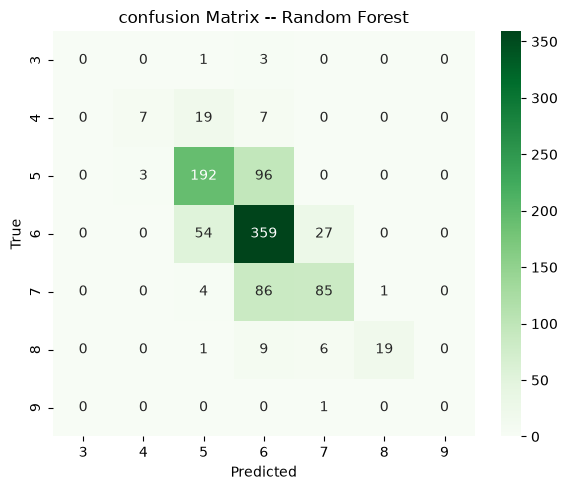

In [ ]:
rf = RandomForestClassifier(n_estimators=100, random_state=42)
rf.fit(x_train_processed, y_train)

y_pred_rf = rf.predict(x_test_processed)
acc_rf = accuracy_score(y_test, y_pred_rf)

print(f'random Forest test accuracy: {acc_rf:3f}')
print('\n classification_report:\n',)
print(classification_report(y_test, y_pred_rf))

cm_rf = confusion_matrix(y_test, y_pred_rf, labels=rf.classes_)
fig, ax = plt.subplots(figsize=(6,5))
sns.heatmap(cm_rf, annot=True, fmt='d', cmap= 'Greens',
            xticklabels=rf.classes_, yticklabels=rf.classes_,ax=ax)
ax.set_xlabel('Predicted')
ax.set_ylabel('True')
ax.set_title('confusion Matrix -- Random Forest')
plt.tight_layout()
plt.show()

In [ ]:
full_pipeline = SkPipeline([
  ('preprocessor', preprocessor),
  ('classifier', RandomForestClassifier(n_estimators=100, random_state=42)),
])

full_pipeline.fit(x_train, y_train)
y_pred_pipe = full_pipeline.predict(x_test)
print(f'Pipeline test accuracy: {accuracy_score(y_test, y_pred_pipe):.3f}')

#Same result as seperate prep + rf when random_state and data match
print(('Matches seperate RF?', np.array_equal(y_pred_pipe, y_pred_rf)))

Pipeline test accuracy: 0.676
('Matches seperate RF?', True)


Model Comparison---

In [ ]:
log_reg = LogisticRegression(max_iter = 1000, random_state=42)
print('preprocessed x train values:', x_train_processed[:5])
print('preprocessed y train values:', y_train.head(5))
log_reg.fit(x_train_processed, y_train)

y_pred_lr = log_reg.predict(x_test_processed)
y_proba_lr = log_reg.predict_proba(x_test_processed)

print('First 5 predictions:', y_pred_lr[:5])
print('Probability shape:', y_proba_lr.shape)
print('Quality order:', log_reg.classes_)

preprocessed x train values: [[-1.476971   -0.67694919 -0.77763088 -0.39646342 -0.876675    0.0902539
   0.27365376 -1.01515224  0.72737311 -1.57293393  0.81143588]
 [-0.77383236  0.2257692  -0.19918487 -0.94515423 -0.50239008  0.26552765
  -0.76294741 -1.63357016  0.46563703 -0.87032539  1.95462679]
 [-0.53945282 -0.07513693 -0.11654972 -0.37686732  9.08866078  1.49244391
   0.83907259  0.24828222 -0.45043924 -0.07989079 -0.90335049]
 [-0.65664259 -0.57664715  0.04872057 -1.02353863 -0.45560447 -0.20186902
  -0.99853859 -1.47730327 -0.84304335  2.20358697  0.89309237]
 [-1.82854031  0.2257692  -1.43871203 -0.43565562 -0.78310377  0.0902539
  -0.90430212 -1.18139362  0.72737311 -1.1338036   1.05640536]]
preprocessed y train values: 3690    7
3463    7
683     5
3698    6
3253    8
Name: quality, dtype: int64
First 5 predictions: [5 6 6 6 7]
Probability shape: (980, 7)
Quality order: [3 4 5 6 7 8 9]


 Logistic Regression test accuracy: 0.549

 Classification report:

              precision    recall  f1-score   support

           3       0.00      0.00      0.00         4
           4       0.50      0.06      0.11        33
           5       0.59      0.53      0.56       291
           6       0.53      0.76      0.63       440
           7       0.56      0.27      0.37       176
           8       0.00      0.00      0.00        35
           9       0.00      0.00      0.00         1

    accuracy                           0.55       980
   macro avg       0.31      0.23      0.24       980
weighted avg       0.53      0.55      0.52       980



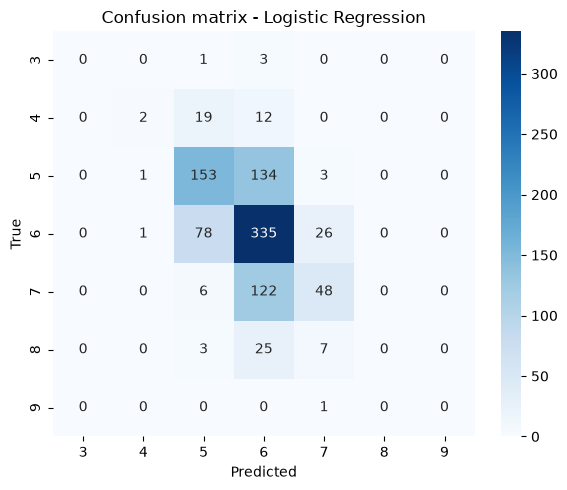

In [ ]:
#Accuracy using confusion matrix
acc_lr = accuracy_score(y_test, y_pred_lr)
print(f' Logistic Regression test accuracy: {acc_lr:.3f}')

print('\n Classification report:\n')
print(classification_report(y_test, y_pred_lr))


cm = confusion_matrix(y_test, y_pred_lr, labels=log_reg.classes_)
fig, ax = plt.subplots(figsize=(6,5))
sns.heatmap(cm, annot = True, fmt = 'd', cmap= 'Blues',
            xticklabels=log_reg.classes_, yticklabels=log_reg.classes_,ax=ax)
ax.set_xlabel('Predicted')
ax.set_ylabel('True')
ax.set_title('Confusion matrix - Logistic Regression')
plt.tight_layout()
plt.show()

                 model  test_accuracy
0  Logistic Regression        0.54898
1        Random Forest        0.67551


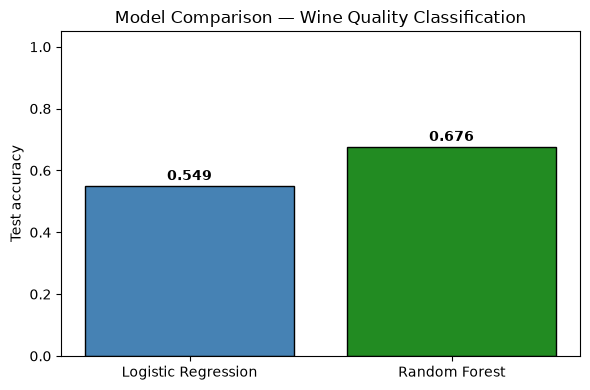


Top 10 feature importances:
                   feature  importance
             num__alcohol    0.116547
             num__density    0.102992
    num__volatile acidity    0.100544
 num__free sulfur dioxide    0.092152
num__total sulfur dioxide    0.090794
                  num__pH    0.086568
           num__chlorides    0.086446
      num__residual sugar    0.086262
         num__citric acid    0.081790
           num__sulphates    0.078324


In [ ]:
results = pd.DataFrame({
    "model": ["Logistic Regression", "Random Forest"],
    "test_accuracy": [acc_lr, acc_rf],
})
print(results)

fig, ax = plt.subplots(figsize=(6, 4))
ax.bar(results["model"], results["test_accuracy"], color=["steelblue", "forestgreen"], edgecolor="black")
ax.set_ylim(0, 1.05)
ax.set_ylabel("Test accuracy")
ax.set_title("Model Comparison — Wine Quality Classification")
for i, v in enumerate(results["test_accuracy"]):
    ax.text(i, v + 0.02, f"{v:.3f}", ha="center", fontweight="bold")
plt.tight_layout()
plt.show()

# Feature importances from pipeline RF
feature_names = full_pipeline.named_steps["preprocessor"].get_feature_names_out()
importances = full_pipeline.named_steps["classifier"].feature_importances_
imp_df = pd.DataFrame({"feature": feature_names, "importance": importances})
imp_df = imp_df.sort_values("importance", ascending=False).head(10)
print("\nTop 10 feature importances:\n", imp_df.to_string(index=False))